In [101]:
import requests
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns

NBA Player API

In [ ]:
#NBA API
url = "https://stats.nba.com/stats/leaguedashplayerstats"

headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10.15; rv:147.0) Gecko/20100101 Firefox/147.0',
    'Accept': '*/*',
    'Accept-Language': 'en-US,en;q=0.9',
    'Referer': 'https://www.nba.com/',
    'Origin': 'https://www.nba.com',
    'Connection': 'keep-alive',
    'Sec-Fetch-Dest': 'empty',
    'Sec-Fetch-Mode': 'cors',
    'Sec-Fetch-Site': 'same-site'
}

#Parameters

params = {
    'College': '',
    'Conference': '',
    'Country': '',
    'DateFrom': '',
    'DateTo': '',
    'Division': '',
    'DraftPick': '',
    'DraftYear': '',
    'GameScope': '',
    'GameSegment': '',
    'Height': '',
    'ISTRound': '',
    'LastNGames': '0',
    'LeagueID': '00',
    'Location': '',
    'MeasureType': 'Base',
    'Month': '0',
    'OpponentTeamID': '0',
    'Outcome': '',
    'PORound': '0',
    'PaceAdjust': 'N',
    'PerMode': 'PerGame',       # Changed from Totals to PerGame
    'Period': '0',
    'PlayerExperience': '',
    'PlayerPosition': '',
    'PlusMinus': 'N',
    'Rank': 'N',
    'Season': '2025-26',
    'SeasonSegment': '',
    'SeasonType': 'Regular Season',
    'ShotClockRange': '',
    'StarterBench': '',
    'TeamID': '0',
    'VsConference': '',
    'VsDivision': '',
    'Weight': ''
}

# Request data

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

response.raise_for_status()

# Convert response to JSON

raw_data = response.json()

# Extract data

result = raw_data['resultSets'][0]
columns = result['headers']
rows = result['rowSet']

# Create DataFrame

df = pd.DataFrame(rows, columns=columns)

# Select columns shown on NBA website

selected_columns = [
    'PLAYER_NAME',
    'TEAM_ABBREVIATION',
    'AGE',
    'GP',
    'W',
    'L',
    'MIN',
    'PTS',
    'FGM',
    'FGA',
    'FG_PCT',
    'FG3M',
    'FG3A',
    'FG3_PCT',
    'FTM',
    'FTA',
    'FT_PCT',
    'OREB',
    'DREB',
    'REB',
    'AST',
    'TOV',
    'STL',
    'BLK',
    'PF',
    'NBA_FANTASY_PTS',
    'FP_HIGH_SCORE',
    'DD2',
    'TD3',
    'PLUS_MINUS'
]
df = df[selected_columns]

# Sort by PTS

df = df.sort_values(
    by='PTS',
    ascending=False
).reset_index(drop=True)

# Rename columns to match NBA website

df = df.rename(columns={
    'PLAYER_NAME': 'PLAYER',
    'TEAM_ABBREVIATION': 'TEAM',
    'FG_PCT': 'FG%',
    'FG3M': '3PM',
    'FG3A': '3PA',
    'FG3_PCT': '3P%',
    'FT_PCT': 'FT%',
    'NBA_FANTASY_PTS': 'TFP',
    'FP_HIGH_SCORE': 'HSFP',
    'PLUS_MINUS': '+/-'
})

# Convert percentages

for col in ['FG%', '3P%', 'FT%']:
    df[col] = (df[col] * 100).round(1)

# Check data

print("Number of players:", len(df))
print("Number of columns:", len(df.columns))
display(df.head(20))

# Save CSV

df.to_csv("nba_players_2025_26.csv", index=False)

NBA Team API

In [ ]:
#NBA TEAM API
time.sleep(5)

# The TEAM stats URL
url = "https://stats.nba.com/stats/leaguedashteamstats"

#Exact headers that worked
headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10.15; rv:147.0) Gecko/20100101 Firefox/147.0',
    'Accept': '*/*',
    'Accept-Language': 'en-US,en;q=0.9',
    'Referer': 'https://www.nba.com/',
    'Origin': 'https://www.nba.com',
    'Connection': 'keep-alive',
    'Sec-Fetch-Dest': 'empty',
    'Sec-Fetch-Mode': 'cors',
    'Sec-Fetch-Site': 'same-site'
}

# Team parameters
params = {
    'College': '',
    'Conference': '',
    'Country': '',
    'DateFrom': '',
    'DateTo': '',
    'Division': '',
    'DraftPick': '',
    'DraftYear': '',
    'GameScope': '',
    'GameSegment': '',
    'Height': '',
    'ISTRound': '',
    'LastNGames': '0',
    'LeagueID': '00',
    'Location': '',
    'MeasureType': 'Base',
    'Month': '0',
    'OpponentTeamID': '0',
    'Outcome': '',
    'PORound': '0',
    'PaceAdjust': 'N',
    'PerMode': 'PerGame',
    'Period': '0',
    'PlayerExperience': '',
    'PlayerPosition': '',
    'PlusMinus': 'N',
    'Rank': 'N',
    'Season': '2025-26',
    'SeasonSegment': '',
    'SeasonType': 'Regular Season',
    'ShotClockRange': '',
    'StarterBench': '',
    'TeamID': '0',
    'VsConference': '',
    'VsDivision': '',
    'Weight': ''
}

# Request data with a longer read timeout
response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=(10, 60) 
)
response.raise_for_status()
    
raw_data = response.json()
result = raw_data['resultSets'][0]
columns = result['headers']
rows = result['rowSet']

df = pd.DataFrame(rows, columns=columns)

# Rename columns
df = df.rename(columns={
    'TEAM_NAME': 'Team',
    'W_PCT': 'WIN_Rate',
    'FG_PCT': 'FG%',
    'FG3_PCT': '3P%',
    'FT_PCT': 'FT%'
})

# Convert percentages
for col in ['WIN_Rate', 'FG%', '3P%', 'FT%']:
    df[col] = (df[col] * 100).round(1)

# Sort by Win %
df = df.sort_values(by='WIN_Rate', ascending=False).reset_index(drop=True)
print(df.head(10))
    
# Save CSV
df.to_csv("nba_team_stats_raw.csv", index=False)



CSV of nba team and nba players

In [52]:
nba_players = pd.read_csv("nba_players_2025_26.csv")
#Strip the spaces
nba_players.columns = nba_players.columns.str.strip()


nba_team = pd.read_csv("nba_team_stats_raw.csv")
#Strip the spaces
nba_team.columns = nba_team.columns.str.strip()


In [28]:
#Check nulls
#print(nba.isnull().sum())
#print(nba_team.isnull().sum())

In [53]:
#Load and Prepare Team Win Rates (API Data)

#15 western teams
western_teams = [
    'Oklahoma City Thunder', 'San Antonio Spurs', 'Denver Nuggets', 
    'Los Angeles Lakers', 'Houston Rockets', 'Minnesota Timberwolves', 
    'Phoenix Suns', 'LA Clippers', 'Portland Trail Blazers', 
    'Golden State Warriors', 'Dallas Mavericks', 'New Orleans Pelicans', 
    'Memphis Grizzlies', 'Sacramento Kings', 'Utah Jazz'
]
west_team_stats = nba_team[nba_team['Team'].isin(western_teams)].copy()

#Rename the team names
team_names = {
    'Oklahoma City Thunder': 'Thunder',
    'Denver Nuggets': 'Nuggets',
    'Golden State Warriors': 'Warriors',
    'Houston Rockets': 'Rockets',
    'LA Clippers': 'Clippers',
    'Los Angeles Lakers': 'Lakers',
    'Memphis Grizzlies': 'Grizzlies',
    'Minnesota Timberwolves': 'Timberwolves',
    'New Orleans Pelicans': 'Pelicans',
    'Dallas Mavericks': 'Mavericks',
    'Phoenix Suns': 'Suns',
    'Portland Trail Blazers': 'Blazers',
    'Sacramento Kings': 'Kings',
    'San Antonio Spurs': 'Spurs',
    'Utah Jazz': 'Jazz'
}
west_team_stats['Team'] = west_team_stats['Team'].replace(team_names)
#Filter only left with Team, W, L, Win tate
west_team_stats = west_team_stats[['Team', 'W', 'L', 'WIN_Rate']]

In [54]:
#Process Player Data (Top 5 Players)
#Each western team
western_abbr = ['DAL', 'DEN', 'GSW', 'HOU', 'LAC', 'LAL', 'MEM', 
                'MIN', 'NOP', 'OKC', 'PHX', 'POR', 'SAC', 'SAS', 'UTA']
west_players = nba_players[nba_players['TEAM'].isin(western_abbr)].copy()

#Rename W to Win
west_players = west_players.rename(columns={'W': 'Win'})
#Game played more than 40
west_players = west_players[west_players['GP'] >= 40]

#Sort players with the most minutes of each team
sorted_players = west_players.sort_values(by=['TEAM', 'MIN'], ascending=[True, False])

#Top 5 players for each team with the most minutes
top_5_players = sorted_players.groupby('TEAM').head(5)

#Calculate 
top_5_averages = top_5_players.groupby('TEAM').agg({
    'PTS': 'mean',
    'REB': 'mean',
    'AST': 'mean',
    'STL': 'mean',
    'BLK': 'mean',
    'FG%': 'mean'
}).round(1)

#rename index
top_5_averages = top_5_averages.reset_index()

#Get to the same name as the upper team names
abbr_to_name = {
    'OKC': 'Thunder', 
    'DEN': 'Nuggets', 
    'GSW': 'Warriors',
    'HOU': 'Rockets', 
    'LAC': 'Clippers', 
    'LAL': 'Lakers',
    'MEM': 'Grizzlies', 
    'MIN': 'Timberwolves', 
    'NOP': 'Pelicans',
    'DAL': 'Mavericks', 
    'PHX': 'Suns', 
    'POR': 'Blazers',
    'SAC': 'Kings', 
    'SAS': 'Spurs', 
    'UTA': 'Jazz'
}
#Replace the abr team to actual real team names and from TEAM to Team for later to merge
top_5_averages['TEAM'] = top_5_averages['TEAM'].replace(abbr_to_name)
top_5_averages = top_5_averages.rename(columns={'TEAM': 'Team'})


In [108]:
#Merge 
final_table = west_team_stats.merge(top_5_averages, on='Team')

#Sort by Win Rate
final_table = final_table.sort_values(by='WIN_Rate', ascending=False)

#Rank
final_table['Rank'] = range(1, len(final_table) + 1)

#Reorder columns
final_table = final_table[['Rank', 'Team', 'W', 'L', 'WIN_Rate', 'PTS', 'REB', 'AST', 'STL', 'BLK', 'FG%']]

#convert to csv
print(final_table)
final_table.to_csv("western_conference_analysis.csv", index=False)

    Rank          Team   W   L  WIN_Rate   PTS  REB  AST  STL  BLK   FG%
0      1       Thunder  64  18      78.0  15.7  4.6  3.1  1.2  0.8  48.2
1      2         Spurs  62  20      75.6  17.1  6.1  4.1  1.0  0.9  46.9
2      3       Nuggets  54  28      65.9  18.4  6.2  5.0  0.9  0.6  50.8
3      4        Lakers  53  29      64.6  19.7  4.9  5.0  1.2  0.4  47.8
4      5       Rockets  52  30      63.4  18.8  6.4  4.3  1.1  0.8  49.0
5      6  Timberwolves  49  33      59.8  17.6  6.3  3.4  1.1  0.8  51.5
6      7          Suns  45  37      54.9  17.1  3.9  3.8  1.1  0.3  42.7
7      8      Clippers  42  40      51.2  17.0  4.6  3.5  1.2  0.3  48.5
8      9       Blazers  42  40      51.2  18.7  4.9  4.0  1.0  0.4  45.2
9     10      Warriors  37  45      45.1  14.6  4.1  3.6  1.1  0.4  43.8
10    11      Pelicans  26  56      31.7  16.7  4.8  3.1  1.2  0.4  46.8
11    12     Mavericks  26  56      31.7  14.6  5.1  2.9  0.9  0.5  45.8
12    13     Grizzlies  25  57      30.5  12.7  4.5

Group the top 5 middle 5 last 5

In [ ]:
west_team = pd.read_csv("western_conference_analysis.csv")
#Top 5
high = west_team.iloc[0:5].copy()
#middle 5
middle = west_team.iloc[5:10].copy()
#last 5
bottom = west_team.iloc[10:15].copy()

stats = ['PTS', 'REB', 'AST', 'STL', 'BLK', 'FG%']

Creat the High vs Middle

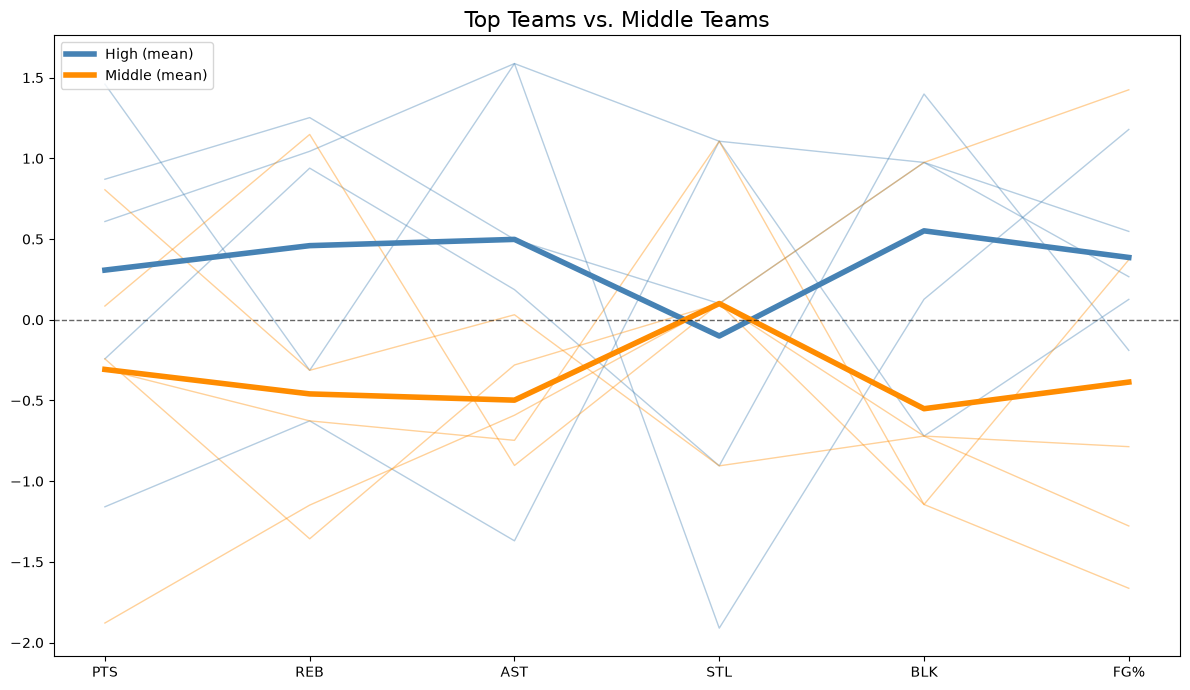

In [ ]:
#Standardize the data (Z-scores)
#Get the high stats and middle 
all_stats = pd.concat([high[stats], middle[stats]])
mean_vals = all_stats.mean()
std_vals = all_stats.std()

#Calculations of z-scores
for stat in stats:
    high[stat] = (high[stat] - mean_vals[stat]) / std_vals[stat]
    middle[stat] = (middle[stat] - mean_vals[stat]) / std_vals[stat]

plt.figure(figsize=(12, 7))
#Plot the THIN background lines
#High teams (Light Blue)
for idx, row in high.iterrows():
    plt.plot(stats, row[stats], color='steelblue', alpha=0.4, linewidth=1)
    
#Middle teams (Light Orange)
for idx, row in middle.iterrows():
    plt.plot(stats, row[stats], color='darkorange', alpha=0.4, linewidth=1)

#THICK average lines
plt.plot(stats, high[stats].mean(), color='steelblue', linewidth=4, label='High (mean)')
plt.plot(stats, middle[stats].mean(), color='darkorange', linewidth=4, label='Middle (mean)')

#Formatting
plt.title('Top Teams vs. Middle Teams', fontsize=16)
plt.axhline(0, color='black', linestyle='--', alpha=0.6, linewidth=1)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()